# BookMatch: гибридная система

## 1. Признаки

Статистики и история рассчитаны по train. Тематические признаки получены из тегов.

In [1]:
from pathlib import Path
import os
import sys
import json

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.data import load_data, split_ratings
from src.features import HybridFeatures

DATA = Path(os.environ.get('BOOKMATCH_DATA', 'data/archive'))
OUTPUT = Path(os.environ.get('BOOKMATCH_OUTPUT', 'reports'))
OUTPUT.mkdir(parents=True, exist_ok=True)
config = json.loads(Path('hybrid.json').read_text())
books, ratings, tags, book_tags = load_data(DATA)
train, validation, test = split_ratings(ratings, config['seed'])
features = HybridFeatures().fit(train, books, tags, book_tags, **config['base_models']['Content'])
display(features.users.head())
display(features.books.head())

         user_mean  user_count  user_std
user_id                                 
1         4.000000           1   0.00000
2         5.000000           1   0.00000
3         1.000000           2   0.00000
4         5.000000           1   0.00000
5         4.666667           3   0.57735

         book_mean  book_count  book_std  tag_fiction  tag_i-own  tag_adult  \
book_id                                                                       
1         4.232323          99  0.890176            1          1          0   
2         4.210000         100  1.037625            1          1          0   
3         3.070707          99  1.465609            1          1          0   
4         4.460000         100  0.833879            1          1          1   
5         3.887755          98  1.082977            1          1          1   

         tag_novels  tag_own-it  tag_contemporary  tag_read-in-2015  ...  \
book_id                                                              ...   
1                 1           1                 1                 0  ...   
2                 1           1                 1                 1  ...   
3                 1           1                 1                 0  ...   
4                 1           1                 1                 

In [2]:
validation_features = features.transform(validation)
display(validation_features.head())
print('Пар:', len(validation_features))
print('Признаков:', validation_features.shape[1] - 2)
print('Пропусков:', validation_features.isna().sum().sum())

   user_id  book_id  user_mean  user_count  user_std  book_mean  book_count  \
0    30034     5534   3.302326          43  0.464701   3.416667          84   
1     5436      693   3.668508         181  1.174049   3.402062          97   
2    10111      967   4.021858         183  0.999760   3.707071          99   
3     7841     4385   3.375000          32  0.707107   4.043011          93   
4    13089     5385   3.444444          72  1.046643   3.125000          96   

   book_std  tag_fiction  tag_i-own  ...  tag_adult-fiction  tag_read-in-2013  \
0  0.996480            1          1  ...                  1                 1   
1  0.996450            1          1  ...                  1                 0   
2  0.823786            1          1  ...                  1                 0   
3  0.858639            1          0  ...                  1                 1   
4  1.068693            1          1  ...                  1                 0   

   tag_book-club  tag_audible  tag_fan

Пар: 45054
Признаков: 27
Пропусков: 0


## 2. Взвешенный гибрид

До 100 кандидатов от каждой модели. Оценки нормализованы в диапазон [0, 1]. Веса подбираются по nDCG@10 на выборке до 3 000 пользователей validation. Параметры базовых моделей зафиксированы в hybrid.json по результатам первого проекта. Test не используется.

In [3]:
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

from src.popularity import Popularity
from src.item_cf import ItemCF
from src.svd import SVDRecommender
from src.hybrid import Hybrid
from src.metrics import ranking_metrics

params = config['base_models']
data = features.data
with threadpool_limits(limits=2):
    models = {
        'Popularity': Popularity(data, **params['Popularity']),
        'Content': features.content,
        'ItemCF': ItemCF(data).fit(**params['ItemCF']),
        'SVD': SVDRecommender(data).fit(train, seed=config['seed'], **params['SVD']),
    }
hybrid = Hybrid(models, config['weights'][0], config['candidates'])
relevant = validation.loc[validation.rating >= 4].set_index('user_id').book_id
if len(relevant) < 2:
    raise ValueError('Для подбора и проверки нужны хотя бы два пользователя validation')
rng = np.random.default_rng(config['seed'])
users = np.sort(rng.choice(np.sort(relevant.index), min(config['validation_users'], len(relevant) // 2), replace=False))
pool = []
with threadpool_limits(limits=2):
    for start in range(0, len(users), 256):
        indices = data.users.get_indexer(users[start:start + 256])
        pool.extend(hybrid.get_candidates(indices))

candidate_hits = [relevant[user] in data.book_ids[items] for user, (items, _) in zip(users, pool)]
print('Доля попаданий в кандидаты:', round(np.mean(candidate_hits), 4))
print('Среднее число кандидатов:', round(np.mean([len(items) for items, _ in pool]), 1))

Доля попаданий в кандидаты: 0.5177
Среднее число кандидатов: 297.8


In [4]:
results = []
for weights in config['weights']:
    vector = np.array([weights[name] for name in models])
    rows = []
    for user, (items, values) in zip(users, pool):
        order = np.argsort(-(values @ vector), kind='stable')[:10]
        recommended = data.book_ids[items[order]]
        row = {}
        for k in [5, 10]:
            precision, recall, ndcg = ranking_metrics(recommended, {relevant[user]}, k)
            row.update({f'precision@{k}': precision, f'recall@{k}': recall, f'ndcg@{k}': ndcg})
        rows.append(row)
    results.append({'weights': json.dumps(weights), **pd.DataFrame(rows).mean().to_dict()})
results = pd.DataFrame(results)
results.to_csv(OUTPUT / 'hybrid_validation.csv', index=False)
display(results)
best = results.loc[results['ndcg@10'].idxmax()]
hybrid = Hybrid(models, json.loads(best.weights), config['candidates'])
user_id = int(users[0])
recommended = hybrid.get_recommendations(user_id, N=10)
assert len(recommended) == len(set(recommended)) == 10
assert not set(recommended) & set(train.loc[train.user_id == user_id, 'book_id'])
display(books.set_index('book_id').loc[recommended, ['title', 'authors']])

                                             weights  precision@5  recall@5  \
0  {"Popularity": 0.25, "Content": 0.25, "ItemCF"...     0.036133  0.180667   
1  {"Popularity": 0.0, "Content": 0.0, "ItemCF": ...     0.037933  0.189667   
2  {"Popularity": 0.0, "Content": 0.1, "ItemCF": ...     0.037667  0.188333   
3  {"Popularity": 0.0, "Content": 0.2, "ItemCF": ...     0.037600  0.188000   
4  {"Popularity": 0.0, "Content": 0.4, "ItemCF": ...     0.036800  0.184000   
5  {"Popularity": 0.05, "Content": 0.15, "ItemCF"...     0.037800  0.189000   
6  {"Popularity": 0.0, "Content": 0.15, "ItemCF":...     0.037600  0.188000   

     ndcg@5  precision@10  recall@10   ndcg@10  
0  0.136489      0.022633   0.226333  0.151069  
1  0.140883      0.024167   0.241667  0.157658  
2  0.140508      0.024500   0.245000  0.158610  
3  0.139819      0.024700   0.247000  0.158620  
4  0.136735      0.024333   0.243333  0.155802  
5  0.140517      0.024667   0.246667  0.158922  
6  0.140407      0.02473

                                                     title  \
book_id                                                      
9209                                           Roller Girl   
2565                                          Wonderstruck   
9381                                            Rain Reign   
8521                                                  Echo   
4323                                              El Deafo   
7305     The War that Saved My Life (The War That Saved...   
5476                                         The Crossover   
9229                               The Fourteenth Goldfish   
8059                                        Fish in a Tree   
9909                                                George   

                                          authors  
book_id                                            
9209                            Victoria Jamieson  
2565                               Brian Selznick  
9381                                Ann M. Mart

Лучшие веса: ItemCF 0,75, Content 0,15, SVD 0,10, Popularity 0. Кандидаты поступают от всех четырёх моделей.

nDCG@10: 0,159363 против 0,157658 у ItemCF (+1,1%). Попаданий в Top-10: 742 против 725. При равных весах nDCG@10 составляет 0,151069.

В пуле в среднем 297,8 книги. Покрытие релевантных книг: 51,77%. Преимущество гибрида пока проверено только на выборке подбора.

## 3. Группы и разнообразие

Группы по истории train: short (1-5 оценок), active (больше 5). Для каждой подбираются веса на validation. Новый пользователь без истории получает Popularity.

MMR снижает балл книг, похожих на уже выбранные. Разнообразие: среднее 1 - cosine между книгами в списке. Охват: доля каталога в выдаче. Выбираем наибольшее разнообразие при потере nDCG@10 не более 1% относительно гибрида с групповыми весами.

In [5]:
from src.segmented_hybrid import SegmentedHybrid
from src.metrics import list_diversity

user_indices = data.users.get_indexer(users)
groups = np.where(data.user_count[user_indices] <= config['short_history'], 'short', 'active')
group_results = []
for weights in config['weights']:
    vector = np.array([weights[name] for name in models])
    scores = []
    for user, (items, values) in zip(users, pool):
        order = np.argsort(-(values @ vector), kind='stable')[:10]
        scores.append(ranking_metrics(data.book_ids[items[order]], {relevant[user]}, 10)[2])
    for group in ['short', 'active']:
        mask = groups == group
        if not mask.any():
            continue
        group_results.append({'group': group, 'users': int(mask.sum()),
                              'weights': json.dumps(weights), 'ndcg@10': np.mean(np.array(scores)[mask])})
group_results = pd.DataFrame(group_results)
group_results.to_csv(OUTPUT / 'hybrid_group_weights.csv', index=False)
selected_groups = group_results.loc[group_results.groupby('group')['ndcg@10'].idxmax()]
group_weights = {group: json.loads(best.weights) for group in ['short', 'active']}
group_weights.update({row.group: json.loads(row.weights) for row in selected_groups.itertuples()})
display(selected_groups)
segmented = SegmentedHybrid(models, json.loads(best.weights), group_weights,
                            config['candidates'], config['short_history'])

     group  users                                            weights   ndcg@10
13  active   1825  {"Popularity": 0.0, "Content": 0.15, "ItemCF":...  0.171473
12   short   1175  {"Popularity": 0.0, "Content": 0.15, "ItemCF":...  0.140554

In [6]:
def summarize_lists(lists):
    rows = []
    for user, items in zip(users, lists):
        precision, recall, ndcg = ranking_metrics(data.book_ids[items], {relevant[user]}, 10)
        rows.append({'precision@10': precision, 'recall@10': recall, 'ndcg@10': ndcg,
                     'diversity@10': list_diversity(models['Content'].features, items)})
    rows = pd.DataFrame(rows)
    summary = []
    for group in ['all', 'short', 'active']:
        mask = np.ones(len(users), dtype=bool) if group == 'all' else groups == group
        if not mask.any():
            continue
        shown = np.concatenate([items for items, keep in zip(lists, mask) if keep])
        summary.append({'group': group, 'users': int(mask.sum()),
                        **rows.loc[mask].mean().to_dict(),
                        'coverage@10': len(np.unique(shown)) / len(data.items)})
    return pd.DataFrame(summary)

baseline_lists = [items[np.argsort(-(values @ hybrid.weights), kind='stable')[:10]]
                  for items, values in pool]
baseline_summary = summarize_lists(baseline_lists).assign(model='Global')
variants = []
summaries = []
for strength in config['diversity']:
    segmented.diversity = strength
    lists = [segmented.rank_candidates(items, values, index)
             for index, (items, values) in zip(user_indices, pool)]
    summary = summarize_lists(lists)
    summaries.append(summary.assign(diversity=strength))
    row = summary.loc[summary.group == 'all'].iloc[0].to_dict()
    variants.append({'diversity': strength, **row})
variants = pd.DataFrame(variants)
reference = variants.loc[variants.diversity == 0, 'ndcg@10'].iloc[0]
allowed = variants[variants['ndcg@10'] >= reference * (1 - config['max_ndcg_loss'])]
chosen = allowed.loc[allowed['diversity@10'].idxmax()]
segmented.diversity = float(chosen.diversity)
variants['selected'] = variants.diversity == segmented.diversity
variants.to_csv(OUTPUT / 'hybrid_diversity.csv', index=False)
display(variants)
segment_summary = pd.concat(summaries, ignore_index=True)
segment_summary = segment_summary[segment_summary.diversity.isin([0, segmented.diversity])].copy()
segment_summary['model'] = np.where(segment_summary.diversity == 0, 'Grouped', 'Grouped + MMR')
segment_summary = pd.concat([baseline_summary, segment_summary], ignore_index=True)
segment_summary.to_csv(OUTPUT / 'hybrid_segments.csv', index=False)
display(segment_summary.drop(columns='diversity'))

   diversity group  users  precision@10  recall@10   ndcg@10  diversity@10  \
0       0.00   all   3000      0.024733   0.247333  0.159363      0.692314   
1       0.05   all   3000      0.025033   0.250333  0.160792      0.715892   
2       0.10   all   3000      0.025133   0.251333  0.161870      0.728446   
3       0.20   all   3000      0.025067   0.250667  0.162284      0.758684   

   coverage@10  selected  
0       0.7614     False  
1       0.7652     False  
2       0.7677     False  
3       0.7703      True  

    group  users  precision@10  recall@10   ndcg@10  diversity@10  \
0     all   3000      0.024733   0.247333  0.159363      0.692314   
1   short   1175      0.021532   0.215319  0.140554      0.695870   
2  active   1825      0.026795   0.267945  0.171473      0.690024   
3     all   3000      0.024733   0.247333  0.159363      0.692314   
4   short   1175      0.021532   0.215319  0.140554      0.695870   
5  active   1825      0.026795   0.267945  0.171473      0.690024   
6     all   3000      0.025067   0.250667  0.162284      0.758684   
7   short   1175      0.021106   0.211064  0.139815      0.781526   
8  active   1825      0.027616   0.276164  0.176750      0.743979   

   coverage@10          model  
0       0.7614         Global  
1       0.4555         Global  
2       0.6273         Global  
3       0.7614        Grouped  
4       0.4555        Grouped  
5       0.6273        Grouped  
6       0.7703  Grouped + MMR  
7       0.4464  Grouped + MMR  
8       0.6412  Group

In [7]:
catalog = books.set_index('book_id')
new_recommendations = segmented.get_recommendations(N=10)
assert len(new_recommendations) == len(set(new_recommendations)) == 10
assert new_recommendations == models['Popularity'].get_recommendations(N=10)
print('Без истории')
display(catalog.loc[new_recommendations, ['title', 'authors']])
for group in ['short', 'active']:
    if not (groups == group).any():
        continue
    user = int(users[np.flatnonzero(groups == group)[0]])
    recommended = segmented.get_recommendations(user, N=10)
    assert len(recommended) == len(set(recommended)) == 10
    assert not set(recommended) & set(train.loc[train.user_id == user, 'book_id'])
    print(group, user)
    display(catalog.loc[recommended, ['title', 'authors']])

Без истории


                                                     title  \
book_id                                                      
7947                                       ESV Study Bible   
6920                   The Indispensable Calvin and Hobbes   
5207     The Days Are Just Packed: A Calvin and Hobbes ...   
6590     The Authoritative Calvin and Hobbes: A Calvin ...   
6361     There's Treasure Everywhere: A Calvin and Hobb...   
9566     Attack of the Deranged Mutant Killer Monster S...   
4483     It's a Magical World: A Calvin and Hobbes Coll...   
5580                The Calvin and Hobbes Lazy Sunday Book   
3275     Harry Potter Boxed Set, Books 1-5 (Harry Potte...   
3753          Harry Potter Collection (Harry Potter, #1-6)   

                                            authors  
book_id                                              
7947     Anonymous, Lane T. Dennis, Wayne A. Grudem  
6920                                 Bill Watterson  
5207                                 Bi

short 37


                                                     title  \
book_id                                                      
9209                                           Roller Girl   
2565                                          Wonderstruck   
9381                                            Rain Reign   
7305     The War that Saved My Life (The War That Saved...   
5476                                         The Crossover   
8521                                                  Echo   
4323                                              El Deafo   
9229                               The Fourteenth Goldfish   
9909                                                George   
2886     The School for Good and Evil (The School for G...   

                                          authors  
book_id                                            
9209                            Victoria Jamieson  
2565                               Brian Selznick  
9381                                Ann M. Mart

active 75


                                                    title  \
book_id                                                     
7320                       Half a War (Shattered Sea, #3)   
746      The Lies of Locke Lamora (Gentleman Bastard, #1)   
1346           Last Argument of Kings (The First Law, #3)   
678                        The Storied Life of A.J. Fikry   
1018                 Royal Assassin (Farseer Trilogy, #2)   
1220                                     Fates and Furies   
1230            Before They Are Hanged (The First Law #2)   
1242                                          The Lowland   
801                             This is Where I Leave You   
458                                        Station Eleven   

                       authors  
book_id                         
7320           Joe Abercrombie  
746                Scott Lynch  
1346           Joe Abercrombie  
678            Gabrielle Zevin  
1018                Robin Hobb  
1220              Lauren Groff  
123

В группах short (1 175 пользователей) и active (1 825) выбраны одинаковые веса. Отдельный подбор по группам улучшения не дал.

Выбран MMR 0,2. nDCG@10 вырос с 0,159363 до 0,162284, разнообразие с 0,6923 до 0,7587, охват каталога с 76,14% до 77,03%.

У active nDCG@10 вырос с 0,171473 до 0,176750, у short снизился с 0,140554 до 0,139815. Общий выигрыш не означает улучшения для каждой группы. Это результаты validation. Для пользователей без истории проверена выдача, качество пока не оценивалось.

## 4. Сравнение моделей

Проверка на остальных пользователях validation с релевантной книгой. Они не участвовали в подборе весов. Параметры не меняются, test не используется.

Without Content отключает контентную оценку с перенормировкой весов, пул кандидатов сохраняется. Grouped проверяет групповые веса, MMR добавляет разнообразие. Остальные признаки из раздела 1 пока не используются.

In [8]:
from src.hybrid_evaluation import compare_models

check_users = np.setdiff1d(relevant.index.to_numpy(), users)
comparison, candidate_recall = compare_models(models, hybrid, segmented, validation, check_users)
comparison.to_csv(OUTPUT / 'hybrid_comparison.csv', index=False)
check_metrics = comparison[comparison.group == 'all'].set_index('model')
display(check_metrics.drop(columns='group').round(6))
print('Пользователей проверки:', len(check_users))
print('Покрытие кандидатов:', round(candidate_recall, 4))

                 users  precision@5  recall@5    ndcg@5  precision@10  \
model                                                                   
Popularity       27243     0.000169  0.000844  0.000583      0.000154   
Content          27243     0.026385  0.131924  0.093232      0.017498   
ItemCF           27243     0.040062  0.200308  0.148714      0.025394   
SVD              27243     0.000103  0.000514  0.000295      0.000136   
Hybrid           27243     0.040253  0.201263  0.149295      0.025592   
Without Content  27243     0.039996  0.199978  0.148784      0.025339   
Grouped          27243     0.040253  0.201263  0.149295      0.025592   
Grouped + MMR    27243     0.041420  0.207099  0.152716      0.026073   

                 recall@10   ndcg@10  diversity@10  coverage@10  
model                                                            
Popularity        0.001542  0.000808      0.618172       0.0018  
Content           0.174981  0.107156      0.601718       0.9293  
ItemC

Пользователей проверки: 27243
Покрытие кандидатов: 0.5266


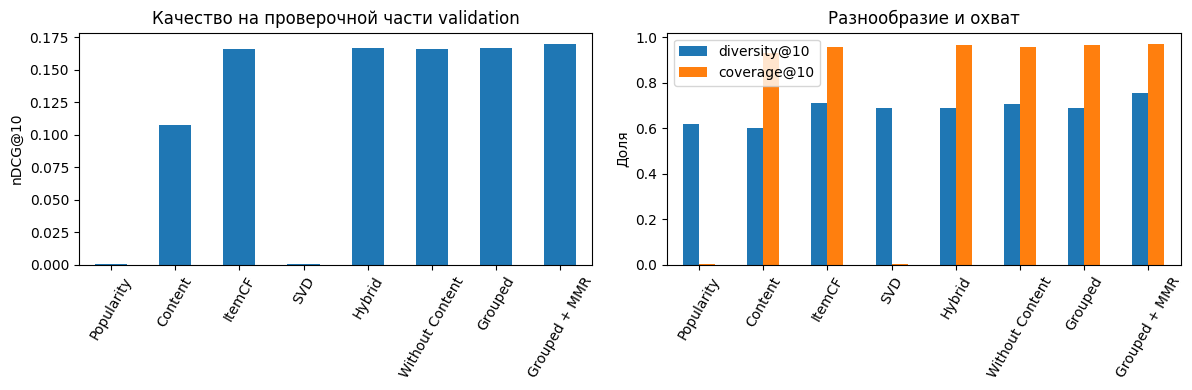

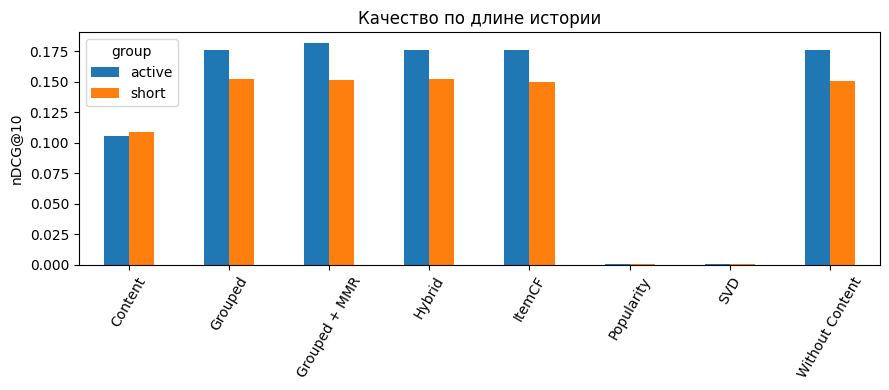

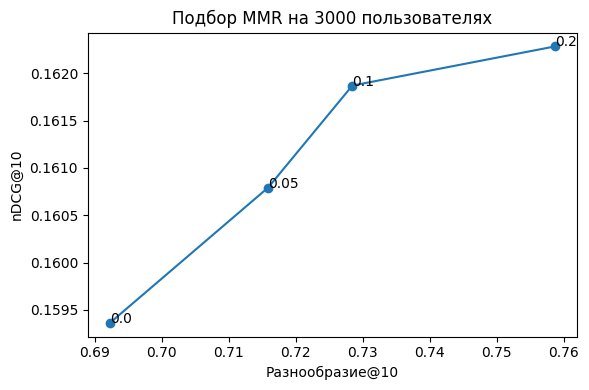

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
check_metrics['ndcg@10'].plot.bar(ax=axes[0], rot=60)
axes[0].set(title='Качество на проверочной части validation', ylabel='nDCG@10', xlabel='')
check_metrics[['diversity@10', 'coverage@10']].plot.bar(ax=axes[1], rot=60)
axes[1].set(title='Разнообразие и охват', ylabel='Доля', xlabel='')
plt.tight_layout()
plt.show()

segment_scores = comparison[comparison.group != 'all'].pivot(index='model', columns='group', values='ndcg@10')
segment_scores.plot.bar(figsize=(9, 4), rot=60)
plt.title('Качество по длине истории')
plt.ylabel('nDCG@10')
plt.xlabel('')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(variants['diversity@10'], variants['ndcg@10'], marker='o')
for row in variants.to_dict('records'):
    ax.annotate(str(row['diversity']), (row['diversity@10'], row['ndcg@10']))
ax.set(title=f'Подбор MMR на {len(users)} пользователях', xlabel='Разнообразие@10', ylabel='nDCG@10')
plt.tight_layout()
plt.show()

На 27 243 пользователях проверки лучший общий результат у Grouped + MMR: nDCG@10 = 0,170024 против 0,165978 у ItemCF (+2,4%). Recall@10 вырос с 0,2539 до 0,2607.

Без контентной оценки nDCG@10 гибрида снижается с 0,166930 до 0,166027. Контент помогает, но вклад небольшой. Групповые веса результата не меняют, поскольку совпадают.

MMR повышает разнообразие с 0,6877 до 0,7549 и охват с 96,71% до 97,18%. У active nDCG@10 растёт с 0,176382 до 0,181613, у short снижается с 0,152082 до 0,151820. Общий результат лучше, но для коротких историй обычный гибрид немного точнее.

Popularity и SVD охватывают лишь 0,18% и 0,37% каталога и почти не попадают в релевантные книги. Content охватывает 92,93%, но уступает ItemCF по nDCG@10: 0,107156 против 0,165978. Широкий охват сам по себе не означает точную выдачу.

Покрытие кандидатов составляет 52,66%. Это ограничение для последующего ранжировщика. Результаты относятся к validation, итоговая проверка на test остаётся впереди.

## 5. Нейросетевой ранжировщик

MLP: 32 и 16 нейронов, ReLU, бинарная кросс-энтропия, Adam. Сравниваем 4 оценки моделей и те же оценки с 27 признаками. Архитектура, пары, seed и число эпох одинаковы.

Из train отложено по одной положительной оценке у пользователей с историей от двух книг. Базовые модели и признаки пересчитаны без этих оценок. Для обучения берём до 15 000 пользователей и до 20 неоценённых кандидатов на положительную пару. Это условно отрицательные примеры. Пары вне пула не добавляются.

Доля MLP в гибриде подбирается на той же выборке подбора validation. Остальные используются для сравнения. Test не используется.

sampled_users      15000
covered_users       6809
positive_pairs      6809
negative_pairs    136180
dtype: int64

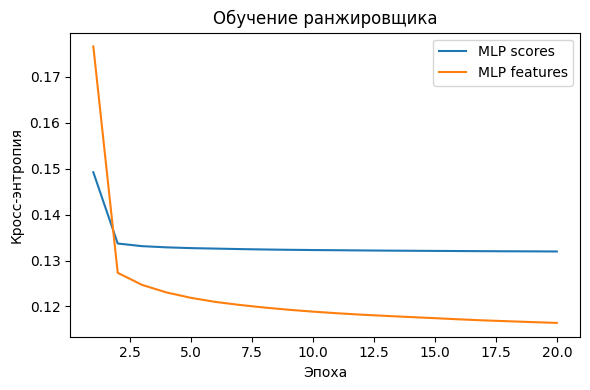

In [10]:
from src.neural import NeuralHybrid
from src.neural_training import training_pairs

neural_config = json.loads(Path('neural.json').read_text())
weights = json.loads(best.weights)
x_train, y_train, training_summary = training_pairs(
    train, books, tags, book_tags, params, weights, neural_config,
)
display(pd.Series(training_summary))
neural = NeuralHybrid(models, weights, features, candidates=config['candidates'])
scores_only = NeuralHybrid(models, weights, features, extra=False, candidates=config['candidates'])
fit_params = {key: neural_config[key] for key in ['hidden', 'epochs', 'seed']}
neural.fit(x_train, y_train, **fit_params)
scores_only.fit(x_train[:, :len(models)], y_train, **fit_params)
losses = pd.DataFrame({'epoch': np.arange(1, neural_config['epochs'] + 1),
                      'MLP scores': scores_only.loss, 'MLP features': neural.loss})
losses.to_csv(OUTPUT / 'neural_loss.csv', index=False)
losses.plot(x='epoch', y=['MLP scores', 'MLP features'], figsize=(6, 4))
plt.title('Обучение ранжировщика')
plt.ylabel('Кросс-энтропия')
plt.xlabel('Эпоха')
plt.tight_layout()
plt.show()

In [11]:
predictions = []
with threadpool_limits(limits=2):
    for start in range(0, len(users), 256):
        predictions.extend(neural.predict_pool(users[start:start + 256], pool[start:start + 256]))
blend_results = []
for blend in neural_config['blend']:
    rows = []
    for user, (items, values), scores in zip(users, pool, predictions):
        selected = neural.rank_candidates(items, values, scores, blend=blend)
        p, r, n = ranking_metrics(data.book_ids[selected], {relevant[user]}, 10)
        rows.append({'precision@10': p, 'recall@10': r, 'ndcg@10': n})
    blend_results.append({'blend': blend, **pd.DataFrame(rows).mean().to_dict()})
blend_results = pd.DataFrame(blend_results)
neural.blend = float(blend_results.loc[blend_results['ndcg@10'].idxmax(), 'blend'])
blend_results['selected'] = blend_results.blend == neural.blend
blend_results.to_csv(OUTPUT / 'neural_validation.csv', index=False)
display(blend_results)

   blend  precision@10  recall@10   ndcg@10  selected
0   0.00      0.024733   0.247333  0.159363     False
1   0.25      0.025900   0.259000  0.166192     False
2   0.50      0.025933   0.259333  0.168556     False
3   0.75      0.026200   0.262000  0.169643      True
4   1.00      0.026100   0.261000  0.169203     False

                  ndcg@10  recall@10  diversity@10  coverage@10
model                                                          
Popularity       0.000808   0.001542      0.618172       0.0018
Content          0.107156   0.174981      0.601718       0.9293
ItemCF           0.165978   0.253937      0.710667       0.9590
SVD              0.000562   0.001358      0.687505       0.0037
Hybrid           0.166930   0.255919      0.687709       0.9671
Without Content  0.166027   0.253386      0.705147       0.9574
Grouped          0.166930   0.255919      0.687709       0.9671
Grouped + MMR    0.170024   0.260728      0.754947       0.9718
MLP scores       0.166616   0.256213      0.702586       0.9637
MLP features     0.175589   0.268583      0.756731       0.8841
Neural hybrid    0.177529   0.271483      0.739227       0.9159

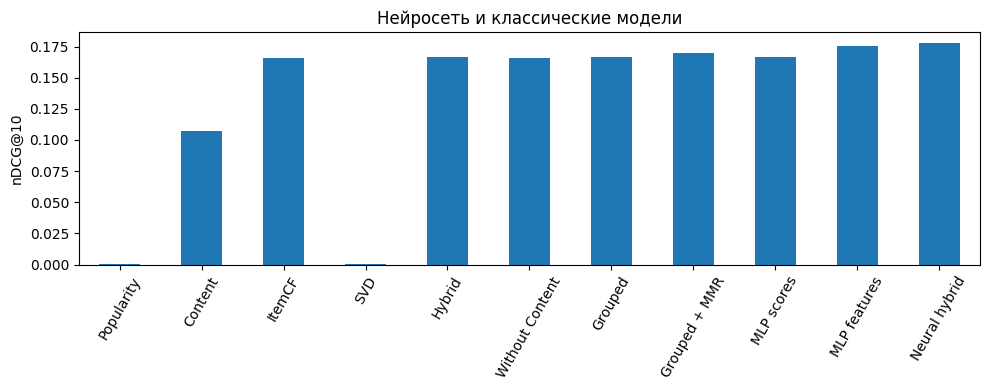

                                           title  \
book_id                                            
9209                                 Roller Girl   
9381                                  Rain Reign   
8059                              Fish in a Tree   
9909                                      George   
4323                                    El Deafo   
9229                     The Fourteenth Goldfish   
9802     Rump: The True Story of Rumpelstiltskin   
8521                                        Echo   
4097                             This One Summer   
5516      Three Times Lucky (Tupelo Landing, #1)   

                                 authors  
book_id                                   
9209                   Victoria Jamieson  
9381                       Ann M. Martin  
8059                  Lynda Mullaly Hunt  
9909                           Alex Gino  
4323              Cece Bell, David Lasky  
9229     Jennifer L. Holm, Tad Carpenter  
9802                     Liesl 

In [12]:
from src.neural_evaluation import compare_neural

neural_comparison = compare_neural(neural, scores_only, validation, check_users, config['short_history'])
neural_comparison.to_csv(OUTPUT / 'neural_comparison.csv', index=False)
all_models = pd.concat([comparison, neural_comparison], ignore_index=True)
all_metrics = all_models[all_models.group == 'all'].set_index('model')
display(all_metrics[['ndcg@10', 'recall@10', 'diversity@10', 'coverage@10']].round(6))
all_metrics['ndcg@10'].plot.bar(figsize=(10, 4), rot=60)
plt.title('Нейросеть и классические модели')
plt.ylabel('nDCG@10')
plt.xlabel('')
plt.tight_layout()
plt.show()
recommended = neural.get_recommendations(int(users[0]), N=10)
assert len(recommended) == len(set(recommended)) == 10
assert not set(recommended) & set(train.loc[train.user_id == users[0], 'book_id'])
display(books.set_index('book_id').loc[recommended, ['title', 'authors']])

В обучающий пул попали 6 809 из 15 000 целевых книг. Получено 6 809 положительных и 136 180 условно отрицательных пар.

На проверочной части validation дополнительные признаки повышают nDCG@10 MLP с 0,166616 до 0,175589 (+5,4%). Доля MLP 0,75 выбрана на выборке подбора. Нейросетевой гибрид даёт nDCG@10 = 0,177529 против 0,170024 у гибрида с MMR (+4,4%). Recall@10: 0,2715 против 0,2607.

У short nDCG@10 нейросетевого гибрида составляет 0,164643, у active 0,185733. Обе группы лучше гибрида с MMR: 0,151820 и 0,181613.

Компромисс: охват каталога снизился с 97,18% до 91,59%, разнообразие с 0,7549 до 0,7392. По точности на validation выбран бы нейросетевой гибрид, по охвату и разнообразию лучше гибрид с MMR. Итоговая оценка на test ещё не выполнена.

## 6. Единый запуск

`python -m src.pipeline` выполняет этапы 1-5 и сохраняет таблицы, рекомендации и выполненный ноутбук. Пути задаются через `--data` и `--output`.

In [13]:
requested_user = os.environ.get('BOOKMATCH_USER')
user_id = int(requested_user) if requested_user else int(users[0])
recommended = neural.get_recommendations(user_id, N=10)
recommendations = books.set_index('book_id').loc[recommended, ['title', 'authors']].reset_index()
recommendations.insert(0, 'rank', np.arange(1, len(recommendations) + 1))
recommendations.insert(0, 'user_id', user_id)
recommendations.to_csv(OUTPUT / 'recommendations.csv', index=False)
display(recommendations)

   user_id  rank  book_id                                    title  \
0       37     1     9209                              Roller Girl   
1       37     2     9381                               Rain Reign   
2       37     3     8059                           Fish in a Tree   
3       37     4     9909                                   George   
4       37     5     4323                                 El Deafo   
5       37     6     9229                  The Fourteenth Goldfish   
6       37     7     9802  Rump: The True Story of Rumpelstiltskin   
7       37     8     8521                                     Echo   
8       37     9     4097                          This One Summer   
9       37    10     5516   Three Times Lucky (Tupelo Landing, #1)   

                           authors  
0                Victoria Jamieson  
1                    Ann M. Martin  
2               Lynda Mullaly Hunt  
3                        Alex Gino  
4           Cece Bell, David Lasky  
5  Jenn